<a href="https://colab.research.google.com/github/ricvazquez/ColabFiles/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nombre: Ricardo Vazquez Macias
Matricula: 273509

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [14]:
## Importamos todo lo que necesitamos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from google.colab import drive
drive.mount('/content/drive')

## Abrimos el csv que traemos desde el drive
df = pd.read_csv('/content/drive/MyDrive/ClassFiles/college.csv')
## Creo una copia para diferenciar el de one hot encoding del otro
df2 = df.copy()
df = df[['salary','cost','location']]
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,salary,cost,location
0,119000,189300,NE
1,121000,189600,NE
2,123000,188400,NE
3,123000,188700,NE
4,110000,194200,NE


In [15]:
## Cambiamos type de location a category
# print(df.dtypes)
df['location'] = df['location'].astype('category')
df.dtypes

,0
salary,int64
cost,int64
location,category


In [16]:
## Vwemos la informacion basica de salary y cost
df[['salary','cost']].describe()

,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000


In [17]:
## Revisamos cuantos valores diferentes hay en location
df['location'].value_counts()

,count
location,
NE,25
W,21
S,20
MW,19


In [18]:
## Hacemos el one hot encoding separando esos valores en columnas para volverlas numericas
df = pd.get_dummies(df, columns=['location'], drop_first=True)
df.head()

,salary,cost,location_NE,location_S,location_W
0,119000,189300,True,False,False
1,121000,189600,True,False,False
2,123000,188400,True,False,False
3,123000,188700,True,False,False
4,110000,194200,True,False,False


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




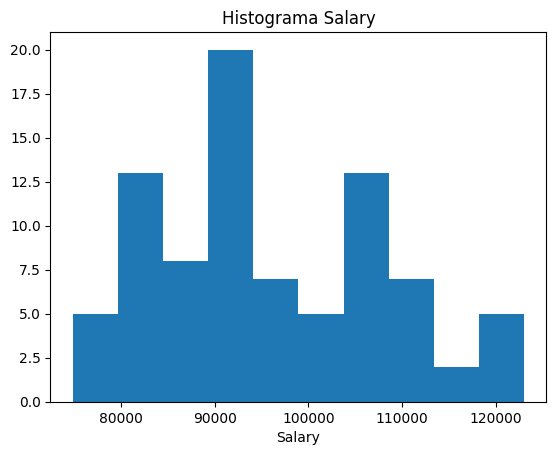

In [19]:
plt.hist(df['salary'])
plt.title('Histograma Salary')
plt.xlabel('Salary')
plt.show()

Con el histograma podemos ver las cantidades y como se repiten en el dataset viendo que las que menos se repiten son las mas altas y la que mas se repiten son las medias bajas

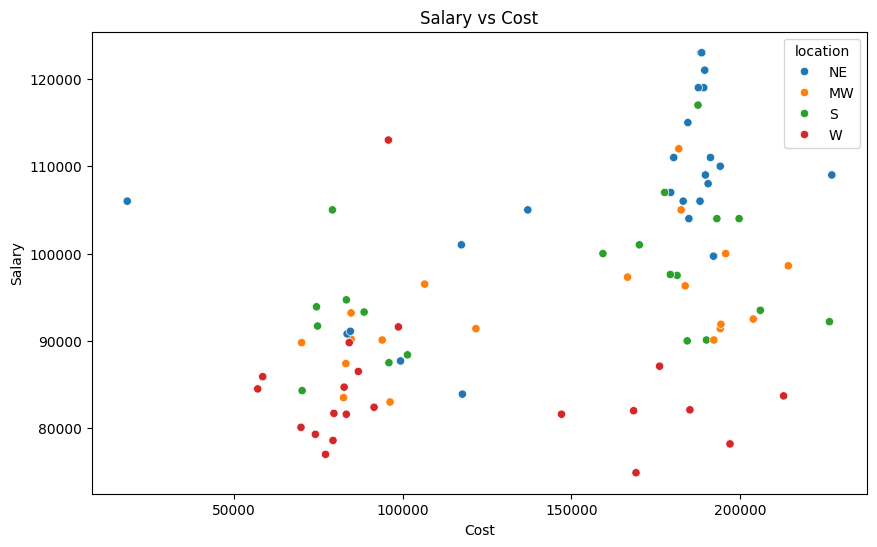

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df2, x='cost', y='salary', hue='location')
plt.title('Salary vs Cost')
plt.xlabel('Cost')
plt.ylabel('Salary')
plt.show()

Ahora podemos ver la relacion del salario, locacion y costo. Podemos ver que no hay una separacion clara para hacer una regresion lineal, unas se sobre ponen a otras

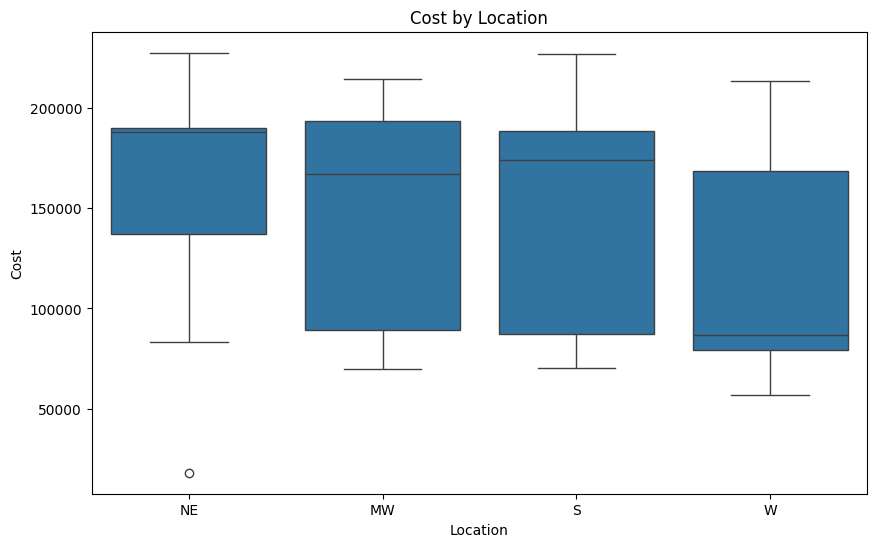

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df2, x='location', y='cost')
plt.title('Cost by Location')
plt.xlabel('Location')
plt.ylabel('Cost')
plt.show()

Aqui podemos ver la variacion del costo segun la localidad, y como se va comportando, siendo el south y el MW los que mas abarcan

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [22]:
x = df.drop('salary', axis=1)
y = df['salary']

# print(x)
# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(x,y)
y_pred = model.predict(x)
for coef, name in zip(model.coef_, x.columns):
  print("Columna:", name, "Coeficiente:", round(coef,2))


# print(model.coef_)

Columna: cost Coeficiente: 0.06
Columna: location_NE Coeficiente: 12032.82
Columna: location_S Coeficiente: 2800.35
Columna: location_W Coeficiente: -7721.42


Aqui podemos ver como cost representa el cambio de salary por cada unidad que aumente cost, en este caso nos dice que cada vez que cost aumente una unidad, salary deberia de aumentar 0.06. y los coeficientes de las variables location que agregamos, y asi con cada columna representada

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

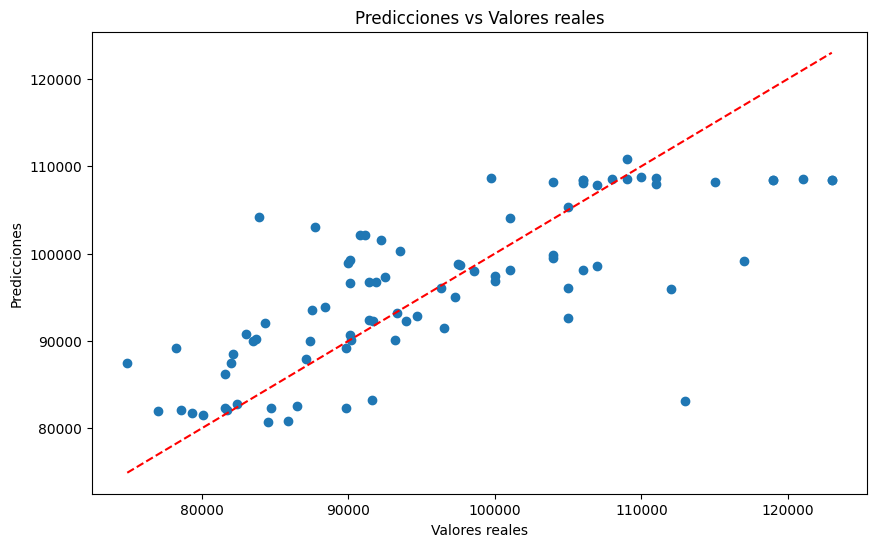

In [23]:
plt.figure(figsize=(10, 6))
plt.scatter(y, y_pred)
plt.plot([min(y), max(y)], [min(y), max(y)], color='red', linestyle='--')
plt.xlabel('Valores reales')
plt.ylabel('Predicciones')
plt.title('Predicciones vs Valores reales')
plt.show()

Text(0, 0.5, 'Residuos')

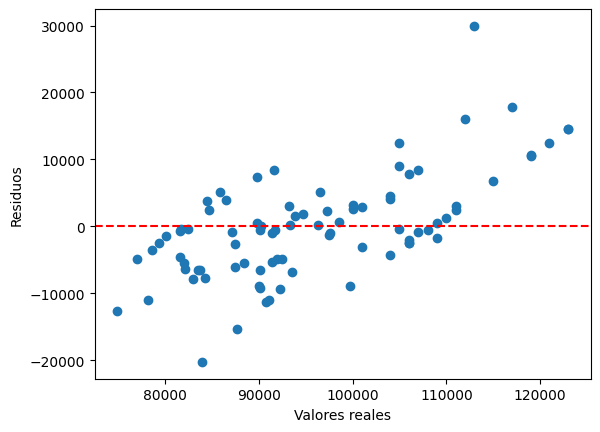

In [24]:
residuos = y - y_pred
plt.scatter(y, residuos)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Valores reales')
plt.ylabel('Residuos')

Podemos ver como si hay cierta diferencia entre los valores reales y las predicciones, ya que hay muchos puntos alejados de la linea roja. Se pueden observar muchos outliers de los dos lados lo cual nos dice que el modelo pudiera ser de poca confiabilidad

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [25]:
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print("MSE:", round(mse,2))
print("R² Score:", round(r2,2))

MSE: 60480269.15
R² Score: 0.57


Con un error cuadratico medio tan alto y tan solo 57% de fiabilidad, lo mas seguro seria concluir que el modelo no es bueno. y no deberia de ser usado para predecir salarios

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [26]:
model = smf.ols("salary ~ cost + location", data=df2).fit()
anova = sm.stats.anova_lm(model, typ=2)
print(anova)

                sum_sq    df          F        PR(>F)
location  4.071774e+09   3.0  21.121259  3.570975e-10
cost      7.878166e+08   1.0  12.259774  7.600629e-04
Residual  5.140823e+09  80.0        NaN           NaN


podemos ver como el p-valor es muy bajo lo cual nos dice que esta muy ligada con salario, al igual que cost tambien tiene un valor muy por debajo de 0.05, lo cual tambien nos confirma que esta sumamente relacionado con salario